# Лабораторна робота №5. Донавчання моделей
## Власний проєкт — SmartNotify

**Мета роботи:** донавчити багатомовну модель **XLM-RoBERTa** для класифікації українських повідомлень на чотири рівні пріоритету: `Low`, `Medium`, `High`, `Critical`.

**Запуск:** Google Colab → Середовище виконання → Змінити тип середовища → **T4 GPU**. Під час завантаження вибрати архів `SmartNotify_Dataset.zip`. Клітинки виконувати **зверху вниз**. Після запуску зберегти `.ipynb` разом із виводом.

## 1.1. Задача й навіщо потрібне донавчання

**SmartNotify** — прототип системи, що визначає пріоритет показу сповіщень. Користувач — людина, яка отримує повідомлення з месенджерів і хоче не пропускати важливі звернення, але й не відволікатися на неважливі.

**Вхід:** JSON з поточним текстом повідомлення та, якщо вони доступні, відправником, його роллю, типом чату, попередніми репліками й контекстом користувача. **Вихід:** один клас із чотирьох (`Low`, `Medium`, `High`, `Critical`).

- **Low:** можна прочитати пізніше без суттєвих наслідків.
- **Medium:** значуще повідомлення, на яке можна відреагувати згодом.
- **High:** потрібна оперативна увага або дія користувача.
- **Critical:** актуальна серйозна загроза, коли затримка реакції може нашкодити.

**Чому fine-tuning?** Правила пріоритету специфічні для нашого застосунку. Готова модель не знає, як ми розрізняємо близькі категорії за персональним контекстом. Класифікаційна голова дозволяє напряму повертати 4 оцінки без довгого промпту й генерації тексту. **RAG** тут не потрібний: ми не шукаємо факти в базі документів, а визначаємо категорію повідомлення за наявними даними.

## 1.2. Модель і дані

**Модель:** `FacebookAI/xlm-roberta-base` — багатомовний **encoder/base** трансформер, який працює з українським текстом. Додаємо класифікаційну голову на 4 виходи. Оновлюватимемо всі ваги моделі й голову — **повне fine-tuning**. Генеративна Instruct-модель для одного класу не обов'язкова.

**Дані:** власний синтетичний **SmartNotify Dataset** — датасет із 2000 ситуацій у `JSONL`. Їх генерували й редагували для цього проєкту; 130 прикладів були використані під час людської перевірки й розробки правил. Більшість інших міток не має незалежного людського підтвердження. Публічну ліцензію датасету окремо не встановлено. Код моделі та умови поширення див. на [сторінці моделі](https://huggingface.co/FacebookAI/xlm-roberta-base).

**Поділ:** `1400 train` (1270 початкових + 130 раніше переглянутих під час розробки), `300 validation`, `300 test`. Кожен клас має по 75 прикладів у validation/test. Схожі сценарії між вибірками можливі.

Подаємо **оригінальний JSON**, а не готовий підготовлений текст: спільний конвертор перетворює поле `input` на формат моделі. Службові метадані та еталонні категорії не потрапляють у вхід.

### 1.2.1. Підготовка середовища й GPU

In [ ]:
%pip -q install "transformers==4.57.6" "accelerate>=1.4,<2" sentencepiece safetensors scikit-learn pandas matplotlib

^C


In [ ]:
import json
import shutil
import time
import zipfile
from collections import Counter
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from IPython.display import Markdown, display
from sklearn.metrics import (accuracy_score, classification_report,
                             confusion_matrix, ConfusionMatrixDisplay, f1_score)
from torch.utils.data import Dataset
from transformers import (AutoModelForSequenceClassification, AutoTokenizer,
                          DataCollatorWithPadding, EarlyStoppingCallback,
                          Trainer, TrainingArguments, set_seed)

MODEL_NAME = "FacebookAI/xlm-roberta-base"
LABELS = ["low", "medium", "high", "critical"]
LABEL2ID = {name: i for i, name in enumerate(LABELS)}
ID2LABEL = {i: name for i, name in enumerate(LABELS)}
MAX_LENGTH = 192
set_seed(42)

assert torch.cuda.is_available(), "Увімкни GPU T4 у налаштуваннях Colab"
print("GPU:", torch.cuda.get_device_name(0))
print("PyTorch:", torch.__version__)

GPU: Tesla T4
PyTorch: 2.14.1+cu130


### 1.2.2. Завантаження SmartNotify Dataset

In [ ]:
ARCHIVE = Path("/content/SmartNotify_Dataset.zip")
if not ARCHIVE.exists():
    from google.colab import files
    print("Завантаж SmartNotify_Dataset.zip")
    files.upload()
assert ARCHIVE.exists(), f"Не знайдено {ARCHIVE.name}"

PREFIX = "SmartNotify_Dataset/"

def load_jsonl(filename):
    with zipfile.ZipFile(ARCHIVE) as z:
        lines = z.read(PREFIX + filename).decode("utf-8").splitlines()
    return [json.loads(line) for line in lines if line.strip()]

train_raw = load_jsonl("train.jsonl")
val_raw = load_jsonl("validation.jsonl")
assert (len(train_raw), len(val_raw)) == (1400, 300)
print("Train:", len(train_raw), "| Validation:", len(val_raw))

Train: 1400 | Validation: 300


### 1.2.3. Однаковий конвертор для ноутбука та застосунку

Перетворюємо структурований JSON на зрозумілий текст із підписаними полями. Відсутні поля пропускаємо. Той самий конвертор потім можна використовувати під час інференсу в SmartNotify.

In [ ]:
%%writefile notification_formatter.py
"""Формат JSON → текст, однаковий для навчання та SmartNotify."""


def format_notification(data: dict) -> str:
    lines = ["Повідомлення: " + data["message"]]

    for key, title in (
        ("sender", "Відправник"),
        ("sender_role", "Роль"),
        ("chat_type", "Тип чату"),
        ("user_context", "Контекст користувача"),
    ):
        if data.get(key):
            lines.append(f"{title}: {data[key]}")

    history = data.get("history") or []
    turns = data.get("history_turns") or []
    if history:
        lines.append("Попередні репліки:")
        if turns and len(turns) == len(history):
            for turn in turns:
                prefix = turn.get("speaker", "") + " — " if turn.get("speaker") else ""
                if turn.get("minutes_ago") is not None:
                    prefix += str(turn["minutes_ago"]) + " хв тому — "
                lines.append("- " + prefix + turn["text"])
        else:
            lines.extend("- " + text for text in history)

    return "\n".join(lines)

Writing notification_formatter.py


In [ ]:
from notification_formatter import format_notification

def prepare_rows(records):
    return [
        {
            "id": record["id"],
            "text": format_notification(record["input"]),
            "label": LABEL2ID[record["output"]["priority"].lower()],
        }
        for record in records
    ]

train_rows = prepare_rows(train_raw)
val_rows = prepare_rows(val_raw)

print("JSON → текст: підготовлено")
print("\nПерший текст моделі:\n", train_rows[0]["text"])
print("Правильний клас:", LABELS[train_rows[0]["label"]])

JSON → текст: підготовлено

Перший текст моделі:
 Повідомлення: Запчастина для твого комп'ютера нарешті в наявності, можеш замовити.
Відправник: Продавець
Тип чату: private
Контекст користувача: Користувач чекає цю запчастину.
Правильний клас: medium


### 1.2.4. Кількість даних і кілька прикладів

Покажемо сам JSON, текст після конвертації та правильну категорію. Це дає змогу перевірити, що модель бачить саме повідомлення й дозволений контекст, а не підказку мітки.

In [ ]:
print("Кількість train:", len(train_rows), "| validation:", len(val_rows))
display(pd.DataFrame([
    {"JSON (input)": json.dumps(r["input"], ensure_ascii=False),
     "Текст для моделі": format_notification(r["input"]),
     "Клас": r["output"]["priority"]}
    for r in train_raw[:3]
]))

Кількість train: 1400 | validation: 300


,JSON (input),Текст для моделі,Клас
0,"{""chat_type"": ""private"", ""message"": ""Запчастин...",Повідомлення: Запчастина для твого комп'ютера ...,medium
1,"{""chat_type"": ""private"", ""message"": ""Підтверди...","Повідомлення: Підтверди, будь ласка, свою учас...",medium
2,"{""chat_type"": ""private"", ""message"": ""Мене рапт...","Повідомлення: Мене раптом перекосило, не можу ...",critical


## 1.3. Модель **до** донавчання — baseline

Для класифікатора з новою випадково ініціалізованою головою було застосовано найпростіше порівняння: завжди передбачати найчастіший клас train. Цей baseline не потребує навчання трансформера й показує мінімальну корисність задачі.

Щоб виконати пункт 1.3 буквально, на тому самому test одразу рахуємо результат baseline до запуску fine-tuning. Для прикладів покажемо 8 прогнозів baseline до навчання.

In [ ]:
y_train = np.array([row["label"] for row in train_rows])
y_val = np.array([row["label"] for row in val_rows])
majority = Counter(y_train).most_common(1)[0][0]

test_raw = load_jsonl("test.jsonl")
test_rows = prepare_rows(test_raw)
assert len(test_rows) == 300
assert not ({r["id"] for r in test_rows} &
            {r["id"] for r in train_rows + val_rows})
y_test = np.array([r["label"] for r in test_rows])
base_pred = np.full(len(y_test), majority)

print("Розподіл train:", {LABELS[i]: int(sum(y_train == i)) for i in range(4)})
print("Baseline (найчастіший клас):", LABELS[majority])
print("Test Accuracy ДО:", round(accuracy_score(y_test, base_pred), 3))
print("Test Macro F1 ДО:", round(f1_score(y_test, base_pred, average="macro", zero_division=0), 3))
display(pd.DataFrame([
    {"Повідомлення": row["text"], "Справжній клас": LABELS[row["label"]],
     "Прогноз ДО": LABELS[majority]}
    for row in test_rows[:8]
]))

Розподіл train: {'low': 419, 'medium': 422, 'high': 351, 'critical': 208}
Baseline (найчастіший клас): medium
Test Accuracy ДО: 0.25
Test Macro F1 ДО: 0.1


,Повідомлення,Справжній клас,Прогноз ДО
0,"Повідомлення: @Андрій, підтверди, будь ласка, ...",medium,medium
1,"Повідомлення: тест показав те, чого ми чекали....",medium,medium
2,"Повідомлення: Рецензенте, підтвердь останню пр...",high,medium
3,Повідомлення: Видалення завершено.\nВідправник...,low,medium
4,Повідомлення: У кого є накладна на ті 6 ящиків...,medium,medium
5,Повідомлення: У нашому районі оголосили негайн...,critical,medium
6,"Повідомлення: у 214 сьогодні ніхто не сидить, ...",high,medium
7,"Повідомлення: Можете підійти тепер? Якщо ні, б...",high,medium


## 1.4. Донавчання XLM-RoBERTa

**Метод:** повне fine-tuning із класифікаційною головою. Оптимізатор AdamW, функція втрат Cross-Entropy. Початкові параметри: 5 епох, learning rate `2e-5`, batch size 4, накопичення градієнтів 4 (ефективний batch 16), fp16, weight decay 0.01. Найкращий checkpoint обираємо за **Macro F1 на validation**. Після навчання побудуємо графік loss і виміряємо час та пам'ять GPU.

### 1.4.1. Токенізація й PyTorch Dataset

In [ ]:
tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)
lengths = [len(tokenizer(row["text"])["input_ids"]) for row in train_rows + val_rows]
print("Довжини токенів: median =", int(np.median(lengths)),
      ", max =", max(lengths))
assert max(lengths) <= MAX_LENGTH, "Є обрізані тексти: збільш MAX_LENGTH"

class NotificationDataset(Dataset):
    def __init__(self, rows):
        self.tokens = tokenizer(
            [row["text"] for row in rows],
            truncation=True, max_length=MAX_LENGTH
        )
        self.labels = [row["label"] for row in rows]

    def __len__(self):
        return len(self.labels)

    def __getitem__(self, index):
        item = {name: values[index] for name, values in self.tokens.items()}
        item["labels"] = self.labels[index]
        return item

train_ds = NotificationDataset(train_rows)
val_ds = NotificationDataset(val_rows)
collator = DataCollatorWithPadding(tokenizer)
print("Перші токени:", tokenizer.convert_ids_to_tokens(train_ds[0]["input_ids"])[:15])

/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


tokenizer_config.json:   0%|          | 0.00/25.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/615 [00:00<?, ?B/s]

sentencepiece.bpe.model:   0%|          | 0.00/5.07M [00:00<?, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

Довжини токенів: median = 38 , max = 111
Перші токени: ['<s>', '▁По', 'від', 'ом', 'лення', ':', '▁За', 'п', 'части', 'на', '▁для', '▁т', 'вого', '▁комп', "'"]


### 1.4.2. Архітектура класифікатора й гіперпараметри

In [ ]:
model = AutoModelForSequenceClassification.from_pretrained(
    MODEL_NAME, num_labels=4, id2label=ID2LABEL, label2id=LABEL2ID
)
print("Параметрів:", f"{sum(p.numel() for p in model.parameters()):,}")

def compute_metrics(result):
    truth = result.label_ids
    predicted = result.predictions.argmax(axis=-1)
    critical = truth == LABEL2ID["critical"]
    return {
        "accuracy": accuracy_score(truth, predicted),
        "f1_macro": f1_score(truth, predicted, average="macro", zero_division=0),
        "critical_recall": (predicted[critical] == 3).mean() if critical.any() else 0.0,
    }

args = TrainingArguments(
    output_dir="/content/smartnotify_lab5_checkpoints",
    num_train_epochs=5,
    learning_rate=2e-5,
    per_device_train_batch_size=4,
    per_device_eval_batch_size=8,
    gradient_accumulation_steps=4,
    weight_decay=0.01,
    warmup_ratio=0.10,
    lr_scheduler_type="linear",
    optim="adamw_torch",
    eval_strategy="epoch",
    save_strategy="epoch",
    logging_strategy="epoch",
    load_best_model_at_end=True,
    metric_for_best_model="f1_macro",
    greater_is_better=True,
    save_total_limit=2,
    fp16=True,
    report_to="none",
    seed=42,
    data_seed=42,
)

trainer = Trainer(
    model=model,
    args=args,
    train_dataset=train_ds,
    eval_dataset=val_ds,
    data_collator=collator,
    processing_class=tokenizer,
    compute_metrics=compute_metrics,
    callbacks=[EarlyStoppingCallback(early_stopping_patience=2)],
)
print("Готово до навчання")

model.safetensors:   0%|          | 0.00/1.12G [00:00<?, ?B/s]

Some weights of XLMRobertaForSequenceClassification were not initialized from the model checkpoint at FacebookAI/xlm-roberta-base and are newly initialized: ['classifier.dense.bias', 'classifier.dense.weight', 'classifier.out_proj.bias', 'classifier.out_proj.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


Параметрів: 278,046,724
Готово до навчання


### 1.4.3. Запуск навчання та замір ресурсів

In [ ]:
torch.cuda.reset_peak_memory_stats()
start = time.perf_counter()
trainer.train()
train_minutes = (time.perf_counter() - start) / 60
peak_gib = torch.cuda.max_memory_allocated() / (1024 ** 3)

print(f"Тривалість: {train_minutes:.1f} хв")
print(f"Пік виділеної GPU-пам'яті: {peak_gib:.2f} GiB")
print("Найкращий checkpoint:", trainer.state.best_model_checkpoint)
print("Найкращий validation Macro F1:", trainer.state.best_metric)

Epoch,Training Loss,Validation Loss,Accuracy,F1 Macro,Critical Recall
1,1.316000,1.205986,0.453333,0.366283,0.000000
2,0.770200,0.493938,0.843333,0.844584,0.826667
3,0.398000,0.409136,0.856667,0.857945,0.826667
4,0.208400,0.368319,0.890000,0.890584,0.866667
5,0.132100,0.405705,0.880000,0.880784,0.880000


Тривалість: 7.8 хв
Пік виділеної GPU-пам'яті: 5.20 GiB
Найкращий checkpoint: /content/smartnotify_lab5_checkpoints/checkpoint-352
Найкращий validation Macro F1: 0.8905844098074801


### 1.4.4. Графік training/validation loss і validation F1

,epoch,loss,eval_loss,eval_f1_macro
0,1.0,1.3160,1.205986,0.366283
1,2.0,0.7702,0.493938,0.844584
2,3.0,0.3980,0.409136,0.857945
3,4.0,0.2084,0.368319,0.890584
4,5.0,0.1321,0.405705,0.880784


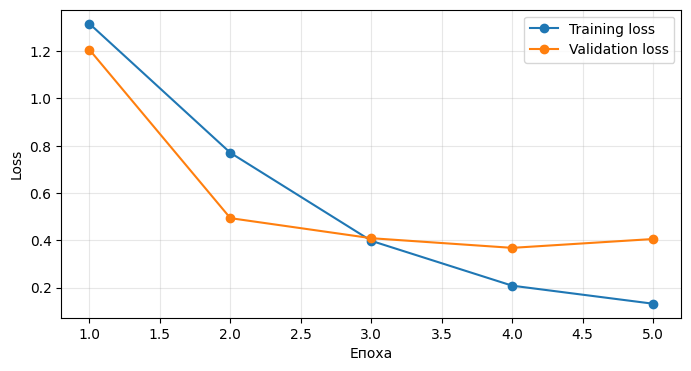

Найкращий checkpoint на validation:


{'eval_loss': 0.3683190941810608, 'eval_accuracy': 0.89, 'eval_f1_macro': 0.8905844098074801, 'eval_critical_recall': 0.8666666666666667, 'eval_runtime': 0.6461, 'eval_samples_per_second': 464.292, 'eval_steps_per_second': 58.81, 'epoch': 5.0}


In [ ]:
logs = pd.DataFrame(trainer.state.log_history)
train_log = logs.dropna(subset=["loss"])[["epoch", "loss"]]
val_log = logs.dropna(subset=["eval_loss"])[["epoch", "eval_loss", "eval_f1_macro"]]
history = pd.merge(train_log, val_log, on="epoch", how="outer")
display(history)

plt.figure(figsize=(8, 4))
plt.plot(train_log["epoch"], train_log["loss"], "o-", label="Training loss")
plt.plot(val_log["epoch"], val_log["eval_loss"], "o-", label="Validation loss")
plt.xlabel("Епоха")
plt.ylabel("Loss")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

print("Найкращий checkpoint на validation:")
print(trainer.evaluate())

**Як аналізувати графік:** якщо training loss зменшується, але validation loss починає зростати, це можлива ознака перенавчання або надмірної впевненості. Остаточний checkpoint вибираємо за зафіксованою метрикою Macro F1, не за результатами test.

## 1.5. Порівняння до/після та аналіз помилок

Порівнюємо baseline та навчений трансформер **на тих самих 300 тестових записах**. Основні метрики: Accuracy і Macro F1; додатково — Critical Recall та середній асиметричний штраф. Останній враховує, що занижувати Critical небезпечніше, ніж трохи завищити Low.

**Матриця штрафів:** рядки — справжній клас, стовпці — прогноз. Це експериментальна матриця SmartNotify, а не універсальний стандарт. Вона використовується **для оцінювання**, не в loss.

In [ ]:
model_pred = trainer.predict(NotificationDataset(test_rows)).predictions.argmax(axis=-1)
COST = np.array([[0, 1, 3, 5], [2, 0, 1, 3],
                 [5, 2, 0, 1], [10, 7, 3, 0]])

def score(pred):
    critical = y_test == LABEL2ID["critical"]
    return {
        "Accuracy": accuracy_score(y_test, pred),
        "Macro F1": f1_score(y_test, pred, average="macro", zero_division=0),
        "Critical Recall": (pred[critical] == LABEL2ID["critical"]).mean() if critical.any() else 0.0,
        "Середній штраф": COST[y_test, pred].mean(),
    }

results = pd.DataFrame({
    "До (most-frequent baseline)": score(base_pred),
    "Після (XLM-RoBERTa)": score(model_pred),
}).T
display(results.round(3))
print("\nЗвіт для кожного класу:\n", classification_report(
    y_test, model_pred, labels=range(4), target_names=LABELS, zero_division=0
))

,Accuracy,Macro F1,Critical Recall,Середній штраф
До (most-frequent baseline),0.250,0.100,0.00,2.500
Після (XLM-RoBERTa),0.903,0.903,0.92,0.243



Звіт для кожного класу:
               precision    recall  f1-score   support

         low       0.87      0.95      0.90        75
      medium       0.91      0.89      0.90        75
        high       0.90      0.85      0.88        75
    critical       0.95      0.92      0.93        75

    accuracy                           0.90       300
   macro avg       0.90      0.90      0.90       300
weighted avg       0.90      0.90      0.90       300



### 1.5.1. Матриця помилок, 8 прикладів до/після та розбір найбільших помилок

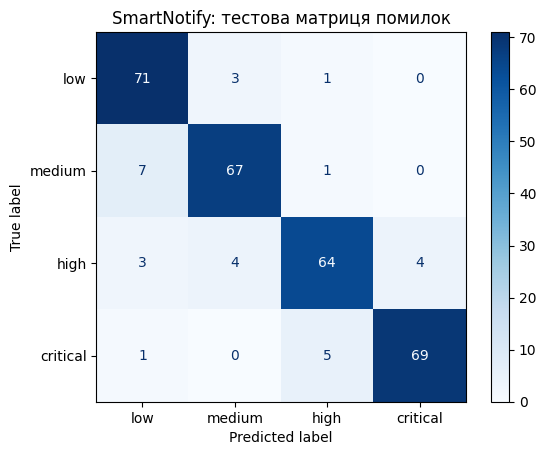

,Повідомлення,Еталон,До,Після
0,Повідомлення: Видалення завершено.\nВідправник...,low,medium,low
1,"Повідомлення: @Андрій, підтверди, будь ласка, ...",medium,medium,medium
2,"Повідомлення: Рецензенте, підтвердь останню пр...",high,medium,high
3,Повідомлення: У нашому районі оголосили негайн...,critical,medium,critical
4,"Повідомлення: у 214 сьогодні ніхто не сидить, ...",low,medium,low
5,"Повідомлення: тест показав те, чого ми чекали....",medium,medium,low
6,"Повідомлення: у 214 сьогодні ніхто не сидить, ...",high,medium,medium
7,Повідомлення: Код для підтвердження входу наді...,critical,medium,critical


Помилок: 29

[10] critical → low
Повідомлення: Тато сказав прощавайте й пішов до мосту, пише що зробить це сьогодні.

[5] high → low
Повідомлення: Адмін просить тимчасово зупинити публікацію сайту: у новій версії відкрита тестова сторінка.
Відправник: Марія
Тип чату: group
Попередні репліки:
- У нас є резервний доступ на випадок збою.

[5] high → low
Повідомлення: Адмін просить тимчасово зупинити публікацію сайту: у новій версії відкрита тестова сторінка.
Відправник: Люба
Роль: колега

[5] high → low
Повідомлення: Я випадково видалив нашу спільну папку з проєктом.
Відправник: Колега

[3] low → high
Повідомлення: @Сергій, відвези будь ласка мій рюкзак, я тебе під під'їздом чекаю
Відправник: Волонтерський чат
Тип чату: group
Контекст користувача: Користувача звати Марко.


In [ ]:
cm = confusion_matrix(y_test, model_pred, labels=range(4))
ConfusionMatrixDisplay(cm, display_labels=LABELS).plot(values_format="d", cmap="Blues")
plt.title("SmartNotify: тестова матриця помилок")
plt.show()

sample_ids = [next(i for i, row in enumerate(test_rows) if row["label"] == c)
              for c in range(4)]
sample_ids += [next(i for i, row in enumerate(test_rows)
                    if row["label"] == c and i not in sample_ids) for c in range(4)]
display(pd.DataFrame([
    {"Повідомлення": test_rows[i]["text"],
     "Еталон": LABELS[y_test[i]],
     "До": LABELS[base_pred[i]],
     "Після": LABELS[model_pred[i]]}
    for i in sample_ids
]))

mistakes = [(i, int(COST[y_test[i], model_pred[i]]))
            for i in range(len(y_test)) if y_test[i] != model_pred[i]]
print("Помилок:", len(mistakes))
for i, cost in sorted(mistakes, key=lambda x: -x[1])[:5]:
    print(f"\n[{cost}] {LABELS[y_test[i]]} → {LABELS[model_pred[i]]}")
    print(test_rows[i]["text"][:500])

### 1.5.2. Демонстрація впливу контексту

Однакове повідомлення з різними ситуаціями. Ці три приклади потрібні для демонстрації роботи JSON-конвертора і моделі, але **не замінюють** тестовий набір і не є незалежною оцінкою якості.

In [ ]:
examples = [
    {"message": "Можеш скинути фото?", "sender": "Данило", "sender_role": "друг",
     "chat_type": "private", "user_context": "Друг збирає фотографії зі святкування. Відповідь не обмежена часом."},
    {"message": "Можеш скинути фото?", "sender": "Марія", "sender_role": "майстер",
     "chat_type": "private", "history": ["Не можу визначити модель деталі без маркування."],
     "history_turns": [{"speaker": "Марія", "minutes_ago": 3,
                        "text": "Не можу визначити модель деталі без маркування."}],
     "user_context": "Майстер чекає фотографію деталі, щоб завершити терміновий ремонт."},
    {"message": "Можеш скинути фото?", "sender": "Пошукова група",
     "sender_role": "рятувальники", "chat_type": "group",
     "user_context": "Триває пошук зниклої дитини; користувач має її актуальне фото, яке група просить негайно передати."},
]

inputs = tokenizer([format_notification(e) for e in examples],
                   padding=True, truncation=True, max_length=MAX_LENGTH,
                   return_tensors="pt").to(trainer.model.device)
trainer.model.eval()
with torch.inference_mode():
    probabilities = trainer.model(**inputs).logits.softmax(dim=-1).cpu().numpy()

context_table = pd.DataFrame(probabilities, columns=LABELS)
context_table.insert(0, "Контекст", [e["user_context"] for e in examples])
context_table["Прогноз"] = [LABELS[i] for i in probabilities.argmax(axis=1)]
display(context_table.round(3))

,Контекст,low,medium,high,critical,Прогноз
0,Друг збирає фотографії зі святкування. Відпові...,0.977,0.019,0.003,0.002,low
1,"Майстер чекає фотографію деталі, щоб завершити...",0.005,0.060,0.932,0.003,high
2,Триває пошук зниклої дитини; користувач має її...,0.038,0.010,0.393,0.558,critical


### 1.5.3. Збереження моделі

Зберігаємо checkpoint, токенізатор, назви класів і **той самий Python-конвертор**. Ваги **не завантажуємо у GitHub** за вимогами лабораторної. Щоб не втратити їх у Colab, копіюємо папку на Google Drive або завантажуємо архів окремо.

In [ ]:
MODEL_DIR = Path("/content/drive/MyDrive/ai_systems/lab5/smartnotify_lab5_model2")
trainer.save_model(str(MODEL_DIR))
tokenizer.save_pretrained(str(MODEL_DIR))
shutil.copy("notification_formatter.py", MODEL_DIR / "notification_formatter.py")
(MODEL_DIR / "smartnotify_labels.json").write_text(
    json.dumps(LABELS, ensure_ascii=False, indent=2), encoding="utf-8"
)
results.to_csv(MODEL_DIR / "test_metrics.csv", encoding="utf-8-sig")
print("Модель збережено в", MODEL_DIR)
print("Зваж на те, що /content у Colab тимчасовий: збережи папку на Drive або архівом.")

Модель збережено в /content/drive/MyDrive/ai_systems/lab5/smartnotify_lab5_model2
Зваж на те, що /content у Colab тимчасовий: збережи папку на Drive або архівом.


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


## 1.6. Мій звіт
**Задача і чому потрібне донавчання.** SmartNotify визначає пріоритет повідомлення за текстом і доступним контекстом. Правила пріоритетів специфічні для нашого застосунку, тому ми навчаємо окремий класифікатор.

**Модель і дані.** FacebookAI/xlm-roberta-base з головою на 4 класи. Власний синтетичний датасет SmartNotify Dataset (публічна ліцензія не встановлена); pretrained-модель під ліцензією MIT: 1400 train (1270 початкових і 130 раніше переглянутих під час розробки), 300 validation та 300 test; у validation/test по 75 прикладів кожного класу. Дані надходять як JSON і перетворюються на текст конвертором.

**Метрика й результат до донавчання**. Baseline завжди повертає найчастіший клас train. На test: Accuracy = 0.250; Macro F1 = 0.100.

**Метод донавчання й гіперпараметри**. Повне fine-tuning XLM-RoBERTa, Cross-Entropy, learning rate 2e-5, до 5 епох, batch 4, gradient accumulation 4, fp16. Найкращий checkpoint обрано за validation Macro F1. Навчання тривало 7.8 хв, пік пам'яті, виділеної PyTorch на GPU, — 5.20 GiB.

**Результат після донавчання.** Test Accuracy = 0.903; Macro F1 = 0.903; Critical Recall = 0.920. Середній штраф зменшився з 2.500 до 0.243.

**Аналіз помилок.** Неправильних відповідей: 29 із 300. У розділі 10 наведено матрицю помилок, конкретні повідомлення та типи помилок. За потреби тут можна додати власне пояснення, чому модель плутає категорії.

**Висновок.** Донавчання покращило результат відносно простого baseline. Водночас тестові повідомлення синтетичні, а більшість міток не підтверджено незалежно, тому ці числа не гарантують такої самої якості в реальному Telegram. Частина нового test (63 записи) входила до навчання старої моделі, тому порівнювати результати двох моделей на різних test-вибірках напряму не можна. Нове навчання починаємо лише з pretrained XLM-RoBERTa, не зі старого checkpoint.